Data Exploration & Data Cleaning

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

from pathlib import Path

# Individua automaticamente la cartella del progetto
current_dir = Path.cwd().resolve()

BASE_DIR = next(
    (p for p in (current_dir, *current_dir.parents)
     if (p / "Dati").is_dir() and (p / "03_DashBoard").is_dir()),
    None
)

if BASE_DIR is None:
    raise FileNotFoundError("Cartella principale del progetto non trovata")

DATA_DIR = BASE_DIR / "Dati"
DASHBOARD_DIR = BASE_DIR / "03_DashBoard"
MODEL_DIR = DASHBOARD_DIR / "modello_r_f"


In [3]:
file_1 = DATA_DIR / "DataFrame.csv"
df_hotel = pd.read_csv(file_1)

In [4]:
df_hotel.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
df_hotel.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [6]:
df_hotel['previous_cancellations'].value_counts()

previous_cancellations
0     112906
1       6051
2        116
3         65
24        48
11        35
4         31
26        26
25        25
6         22
19        19
5         19
14        14
13        12
21         1
Name: count, dtype: int64

In [7]:
#Questo codice serve per fare un riassunto dei dati 

quality = pd.DataFrame({
    "dtype": df_hotel.dtypes.astype(str),
    "missing_values": df_hotel.isna().sum(),
    "missing_percentage": (df_hotel.isna().mean() * 100).round(2),
    "unique_values": df_hotel.nunique()
})
quality

,dtype,missing_values,missing_percentage,unique_values
hotel,str,0,0.00,2
is_canceled,int64,0,0.00,2
lead_time,int64,0,0.00,479
arrival_date_year,int64,0,0.00,3
arrival_date_month,str,0,0.00,12
arrival_date_week_number,int64,0,0.00,53
arrival_date_day_of_month,int64,0,0.00,31
stays_in_weekend_nights,int64,0,0.00,17
stays_in_week_nights,int64,0,0.00,35
adults,int64,0,0.00,14


In [8]:
# Cambiamo i valori della colonna agent da float a string in quanto rappresenta il codice dell'agenzia e non un numero

df_hotel['agent'] = df_hotel['agent'].astype(str)

In [9]:
# Abbiamo deciso di eliminare la colonna company in quanto presentava oltre il 90% di missing

df_hotel = df_hotel.drop(columns='company')

In [10]:
#Inizialmente abbiamo deciso di rimuovere i duplicati ma guardandoli ci siamo accorti che non sono veri duplicati ma prenotazioni effettuate lo stesso giorno

#df_hotel = df_hotel.drop_duplicates()

In [11]:
df_hotel.isnull().sum()

hotel                                 0
is_canceled                           0
lead_time                             0
arrival_date_year                     0
arrival_date_month                    0
arrival_date_week_number              0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                              4
babies                                0
meal                                  0
country                             488
market_segment                        0
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
assigned_room_type                    0
booking_changes                       0
deposit_type                          0
agent                             16340
days_in_waiting_list                  0


In [12]:
#Sostituiamo le celle vuote con Unknown per avere valori

df_hotel['country'] = df_hotel['country'].fillna('Unknown')

In [13]:
# Abbiamo notato che erano presenti due valori che indicavano la stessa cosa, in prima battuta li abbiamo eliminati, in seguito abbiamo capito che potevamo accorparli con gli altri

#df_hotel = df_hotel.loc[df_hotel['meal'] != 'Undefined']

df_hotel["meal"] = df_hotel["meal"].replace("Undefined", "SC")

In [14]:
#Sostituiamo i valori mancanti con 0

df_hotel["children"] = df_hotel["children"].fillna(0.0) 

In [15]:
#Trasformiamo la colonna children da float ad int in quanto rappresenta un conteggio e quindi ha bisogno di valori interi

df_hotel['children'] = df_hotel['children'].astype(int) 

In [16]:
#df_hotel = df_hotel.dropna()

In [17]:
df_hotel.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 31 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119390 non-null  int64  
 11  babies                          119390 non-null  int64  
 12  meal                       

In [18]:
#Abbiamo creato una colonna con dati in formato orario, il risultato non era efficente quindi abbiamo deciso di lasciare nel formato originale

#df_hotel['arrival_date'] = pd.to_datetime(
    #df_hotel['arrival_date_year'].astype(str) + '-' +
    #df_hotel['arrival_date_month'] + '-' +
    #df_hotel['arrival_date_day_of_month'].astype(str),
    #format='%Y-%B-%d')

In [19]:
#Qui eliminavamo le colonne che formavano la date ma , dato che per la costruzione del modello necessitavamo delle date spaccate per giorno mese anno abbiamo deciso di lasciarle

#eliminare = ['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'arrival_date_week_number']
#df_hotel = df_hotel.drop(columns=eliminare)

In [20]:
#Qui svolgiamo un'analisi sui quantili per cercare di avere una base con cui filtrare i dati di adr ed eliminare outlier

df_hotel['adr'].quantile([0.03, 1])

0.03      30.6
1.00    5400.0
Name: adr, dtype: float64

In [21]:
#Filtriamo gli outlier

df_hotel = df_hotel[(df_hotel['adr'] > df_hotel['adr'].quantile(0.03)) & (df_hotel['adr'] < 5000)] 

#Calcoliamo se sono rimasti più di una notte

df_hotel = df_hotel[df_hotel['stays_in_weekend_nights'] + df_hotel['stays_in_week_nights'] > 0] 

In [22]:
#Abbiamo provato a utilizzare mediane, ma i dati non risultavano coerenti

#mediane = (
    #df_hotel[df_hotel["adr"] > 0]
    #.groupby(["hotel", df_hotel["arrival_date"].dt.month])["adr"]
    #.median())
#mediane_hotel = df_hotel[df_hotel["adr"] > 0].groupby("hotel")["adr"].median()
#mediana_generale = df_hotel.loc[df_hotel["adr"] > 0, "adr"].median()
#mask = df_hotel["adr"] <= 0
#for index in df_hotel.index[mask]:
    #hotel = df_hotel.loc[index, "hotel"]
    #mese = df_hotel.loc[index, "arrival_date"].month
    #if (hotel, mese) in mediane.index:
    #    df_hotel.loc[index, "adr"] = mediane.loc[(hotel, mese)]
    #elif hotel in mediane_hotel.index:
    #    df_hotel.loc[index, "adr"] = mediane_hotel.loc[hotel]
    #else:
    #    df_hotel.loc[index, "adr"] = mediana_generale
#print("Prezzi nulli:", (df_hotel["adr"] == 0).sum())
#print("Prezzi negativi:", (df_hotel["adr"] < 0).sum())
#print("mediane utilizzate:", mediane_hotel,mediana_generale)



In [23]:
df_hotel.info()

<class 'pandas.DataFrame'>
Index: 115787 entries, 2 to 119389
Data columns (total 31 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           115787 non-null  str    
 1   is_canceled                     115787 non-null  int64  
 2   lead_time                       115787 non-null  int64  
 3   arrival_date_year               115787 non-null  int64  
 4   arrival_date_month              115787 non-null  str    
 5   arrival_date_week_number        115787 non-null  int64  
 6   arrival_date_day_of_month       115787 non-null  int64  
 7   stays_in_weekend_nights         115787 non-null  int64  
 8   stays_in_week_nights            115787 non-null  int64  
 9   adults                          115787 non-null  int64  
 10  children                        115787 non-null  int64  
 11  babies                          115787 non-null  int64  
 12  meal                            

In [24]:
#Per semplicità abbiamo deciso di eliminare la variabile agent  

df_hotel = df_hotel.drop(columns='agent') 

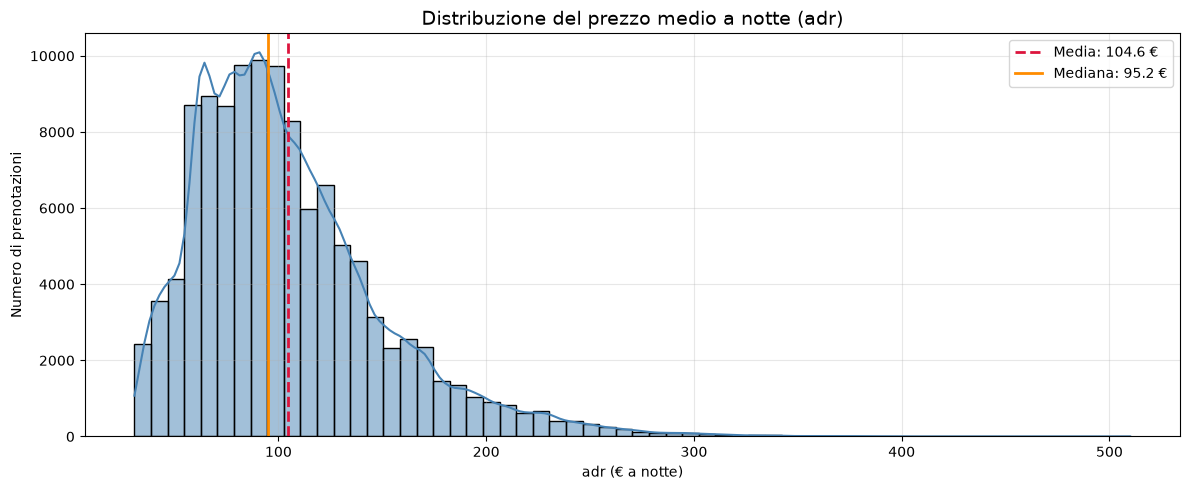

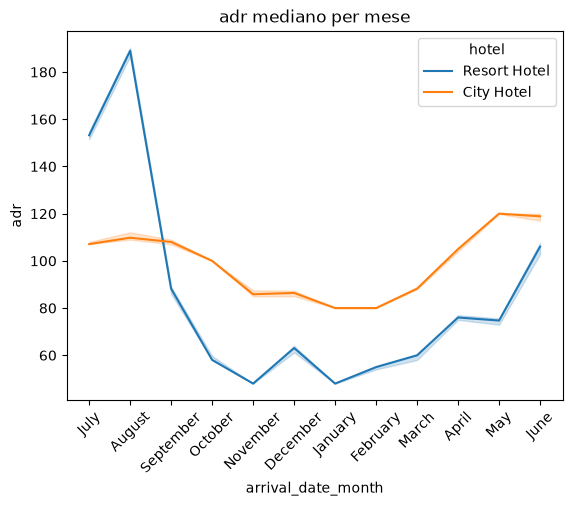

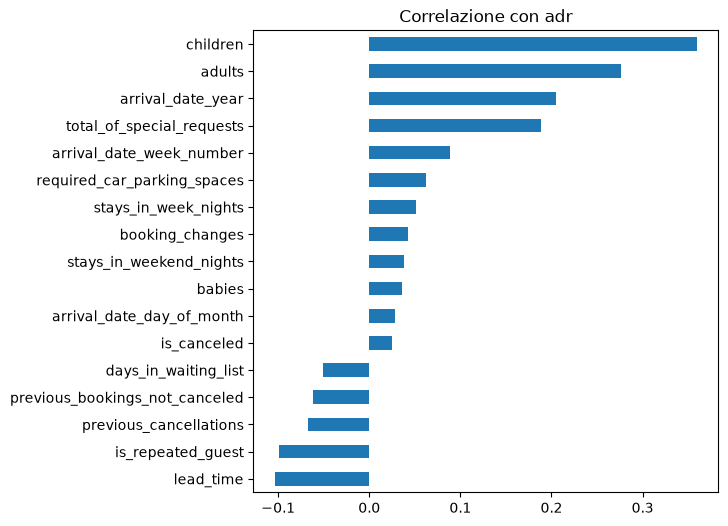

In [25]:
# Distribuzione del prezzo medio a notte

media = df_hotel['adr'].mean()
mediana = df_hotel['adr'].median()
 
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(df_hotel['adr'], bins=60, kde=True, color='steelblue', ax=ax)
 
ax.axvline(media, color='crimson', linestyle='--', linewidth=2, label=f'Media: {media:.1f} €')
ax.axvline(mediana, color='darkorange', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.1f} €')
 
ax.set_title('Distribuzione del prezzo medio a notte (adr)', fontsize=14)
ax.set_xlabel('adr (€ a notte)')
ax.set_ylabel('Numero di prenotazioni')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
 
# adr per hotel e per mese (stagionalità)
sns.lineplot(data=df_hotel, x='arrival_date_month', y='adr', hue='hotel', estimator='median')
plt.title('adr mediano per mese') 
plt.xticks(rotation=45)
plt.show()


# Correlazioni numeriche con il target
corr = df_hotel.select_dtypes('number').corr()['adr'].drop('adr').sort_values()
corr.plot(kind='barh', figsize=(6, 6)) 
plt.title('Correlazione con adr')
plt.show()

In [26]:
#Salviamo il dataframe pulito in un file.scv

df_hotel.to_csv(DATA_DIR / "DataFrame_00.csv", index=False, encoding="utf-8")